In [1]:
import requests
import time
from bs4 import BeautifulSoup as bs
import pandas as pd
import numpy as np
import seaborn as sb
import matplotlib.pyplot as plt
import re
HEADERS = {"User-Agent": "WEBDATASCIENCE OSRS Research Project/1.0, simon.spillane@colorado.edu"}

In [44]:
def get_revisions(title, since=None, until="2026-09-30T23:59:59Z"):
    url = "https://oldschool.runescape.wiki/api.php"
    params = {
        "action": "query",
        "titles": title,
        "prop": "revisions",
        "rvprop": "ids|timestamp|user|size|comment",
        "rvlimit": "max",   # 500 per request, the most the API allows
        "rvstart": until,   # newest edit to include, so the result doesn't change tomorrow
        "format": "json",
    }
    if since:
        params['rvend'] = since
    all_revisions = []
    while True:
        response = requests.get(url, params=params, headers=HEADERS)
        response.raise_for_status()               # stop on HTTP errors
        data = response.json()
        pages = data["query"]["pages"]
        page_id = list(pages.keys())[0]
        all_revisions.extend(pages[page_id].get("revisions", []))
        if "continue" in data:
            params.update(data["continue"])       # ask for the next batch
        else:
            break
    return pd.DataFrame(all_revisions)

ge_revisions = get_revisions("Grand Exchange", since="2021-09-01T00:00:00Z")

print(f"Total revisions: {len(ge_revisions):,}")

print(ge_revisions[["timestamp", "user", "size"]].tail(3).to_string(index=False))


Total revisions: 127
           timestamp           user  size
2021-09-28T11:53:26Z        Shayani 12659
2021-09-28T11:53:10Z 180.216.13.154 12661
2021-09-15T22:28:30Z           Suzu 12659


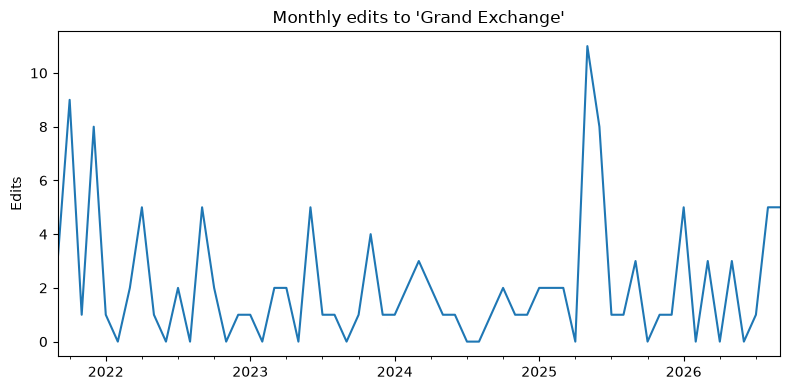

In [47]:

ge_revisions["timestamp"] = pd.to_datetime(ge_revisions["timestamp"])

# Count edits per month
monthly_edits = ge_revisions.set_index("timestamp").resample("ME").size()

fig, ax = plt.subplots(figsize=(8, 4))
monthly_edits.plot(ax=ax)
ax.set_title("Monthly edits to 'Grand Exchange'")
ax.set_ylabel("Edits")
ax.set_xlabel("")
fig.tight_layout()
plt.show()

In [91]:

API = "https://oldschool.runescape.wiki/api.php"
HEADERS = {"User-Agent": "WebDataScience course project - simon.spillane@colorado.edu"}
START_DATE = "2021-15-09T00:00:00Z"
TITLE = "Grand Exchange"


def get_revisions(title, since=START_DATE):
    """All revisions of a page from `since` onward, following continuation."""
    revs = []
    params = {
        "action": "query", "format": "json", "formatversion": 2,
        "prop": "revisions", "titles": title,
        "rvprop": "ids|timestamp|user|comment|size",
        "rvlimit": 500,
        "rvend": since,  # default direction is newest -> oldest, so rvend is the oldest bound
    }
    while True:
        r = requests.get(API, params=params, headers=HEADERS).json()
        revs += r["query"]["pages"][0].get("revisions", [])
        if "continue" not in r:
            break
        params.update(r["continue"])
        time.sleep(0.5)
    return revs


def get_soup(revid):
    """Rendered HTML of one historical revision, as a soup (None if unavailable)."""
    params = {
        "action": "parse", "format": "json", "formatversion": 2,
        "oldid": revid, "prop": "text", "disablelimitreport": 1,
    }
    r = requests.get(API, params=params, headers=HEADERS).json()
    if "parse" not in r:
        return None
    return bs(r["parse"]["text"], "lxml")


def get_is_list(soup):
    start_id = 'Items_regulated_via_item_sink'
    stop_id = 'Exempt_from_tax'

    start = soup.find(id=re.compile(f"^{re.escape(start_id)}$", re.I))
    if start is None:
        print("start anchor not found")
        return []

    results = []
    seen = set()
    skip = {s.lower() for s in [
        "Item sink", "Chambers of Xeric", "Theatre of Blood", "Tombs of Amascut",
        "God Wars Dungeon", "Dagannoth Kings", "Godsword",
        "Nightmare", "Slayer", "Zenyte shard", "Prayer scroll",
    ]}

    for node in start.next_elements:
        if isinstance(node, str):
            continue
        if (node.get('id') or '').lower() == stop_id.lower():
            break
        if (
            node.name == 'a'
            and node.parent.name == 'li'
            and node.get('href', '').startswith('/w/')
            and node.get('title')
        ):
            name = node.get('title')
            key = name.lower()
            if key in skip or key in seen:
                continue
            seen.add(key)
            results.append(name)
    return results


# ---- fetch + parse, oldest first ----
revs = sorted(get_revisions(TITLE), key=lambda r: r["timestamp"])
print(f"{len(revs)} revisions since {START_DATE}")

rows = []
missing_section = 0
for rev in revs:
    soup = get_soup(rev["revid"])
    time.sleep(0.5)
    if soup is None:
        continue
    items = set(get_is_list(soup))
    if not items:
        missing_section += 1
    for item in items:
        rows.append({
            "item": item,
            "revid": rev["revid"],
            "timestamp": rev["timestamp"],
        })

print(f"{missing_section} revisions had no item sink list found")

# ---- first/last seen ----
df = pd.DataFrame(rows)
df["timestamp"] = pd.to_datetime(df["timestamp"], utc=True)

spans = (
    df.groupby("item")["timestamp"]
      .agg(first_seen="min", last_seen="max", n_revisions="nunique")
      .reset_index()
      .sort_values("last_seen")
)

# still listed in the newest revision we could parse?
latest_ts = df["timestamp"].max()
spans["still_listed"] = spans["last_seen"] == latest_ts

spans

112 revisions since 2021-15-09T00:00:00Z
0 revisions had no item sink list found


,item,first_seen,last_seen,n_revisions,still_listed
52,Torn prayer scroll,2022-03-29 07:11:23+00:00,2025-05-29 10:21:05+00:00,60,False
32,Kraken tentacle,2022-03-29 07:11:23+00:00,2025-05-29 10:21:05+00:00,60,False
64,Warrior ring,2022-03-29 07:11:23+00:00,2025-05-29 10:21:05+00:00,60,False
30,Kodai insignia,2022-03-29 07:11:23+00:00,2025-05-29 10:21:05+00:00,60,False
45,Saradomin sword,2022-03-29 07:11:23+00:00,2025-05-29 10:21:05+00:00,60,False
...,...,...,...,...,...
29,Inquisitor's mace,2022-03-29 07:11:23+00:00,2026-10-16 02:02:43+00:00,112,True
31,Kodai wand,2022-03-29 07:11:23+00:00,2026-10-16 02:02:43+00:00,112,True
33,Lightbearer,2023-01-11 12:39:29+00:00,2026-10-16 02:02:43+00:00,94,True
16,Burning claws,2025-05-29 10:49:20+00:00,2026-10-16 02:02:43+00:00,52,True


In [98]:
spans['item'] = (
    spans['item']
    .str.strip()
    .str.lower()
    .str.replace(r"[^\w\s]", "", regex=True)   # drop apostrophes, etc.
    .str.replace(r"\s+", " ", regex=True)       # collapse repeated spaces
)
combined_spans = spans.groupby('item', as_index=False).agg({
    'first_seen': 'min',
    'last_seen': 'max',
    'n_revisions': 'sum',
    'still_listed': 'any',
})

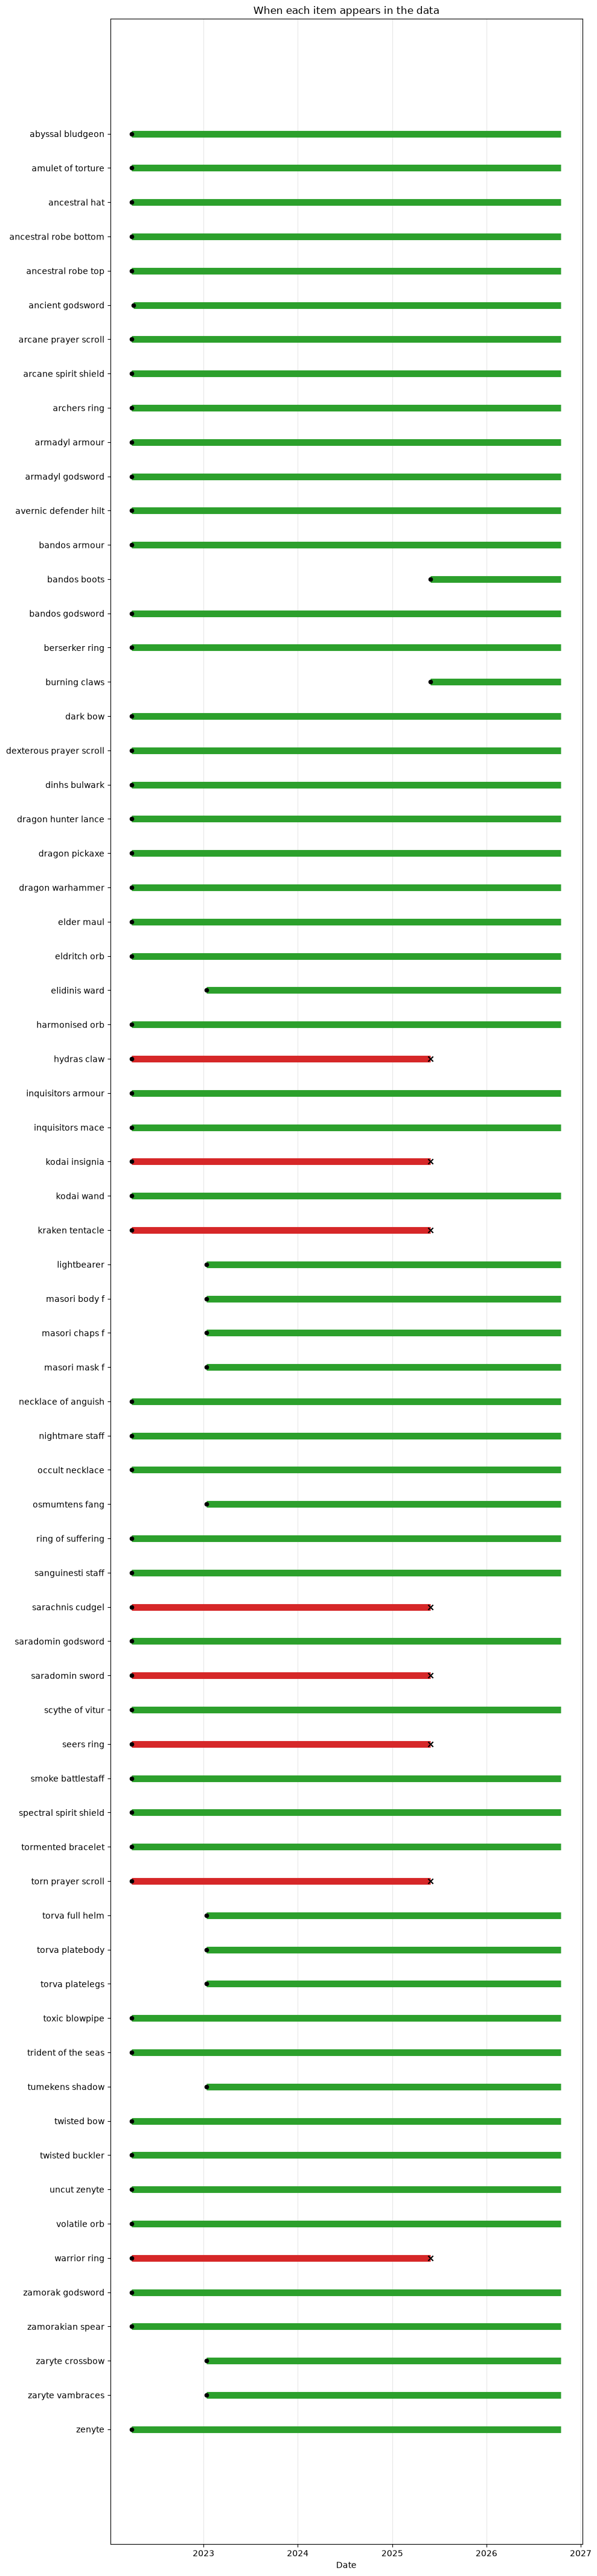

In [99]:
combined_spans["first_seen"] = pd.to_datetime(combined_spans["first_seen"])
combined_spans["last_seen"] = pd.to_datetime(combined_spans["last_seen"])

# Items that appear in the final data point are still "present", not gone
data_end = df["timestamp"].max()
combined_spans["still_here"] = combined_spans["last_seen"] >= data_end

fig, ax = plt.subplots(figsize=(10, 0.6 * len(combined_spans) + 2))

ax.hlines(
    y=combined_spans["item"],
    xmin=combined_spans["first_seen"],
    xmax=combined_spans["last_seen"],
    linewidth=8,
    color=combined_spans["still_here"].map({True: "tab:green", False: "tab:red"}),
)

# Mark entry and exit points
ax.scatter(combined_spans["first_seen"], combined_spans["item"], color="black", zorder=3, s=20)
ax.scatter(combined_spans.loc[~combined_spans["still_here"], "last_seen"],
           combined_spans.loc[~combined_spans["still_here"], "item"],
           marker="x", color="black", zorder=3)

ax.invert_yaxis()  # earliest item at the top, matching the sort order
ax.xaxis.set_major_locator(mdates.AutoDateLocator())
ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(ax.xaxis.get_major_locator()))
ax.set_xlabel("Date")
ax.set_title("When each item appears in the data")
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

In [101]:
combined_spans.to_csv("ItemSinkList.csv", index=False)